# SESA root-zone soil moisture: testing for a wet → dry trend reversal (GLEAM)

**Question:** did GLEAM root-zone soil moisture (SMrz) over southeastern South America switch from a wetting trend to a drying trend (or the reverse), and when?

## Imports

In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Degrees of freedom")
%matplotlib inline

## Settings

In [2]:
# Yearly GLEAM v4.3a monthly files (1980-2025). The merged files ../data/SMrz_GLEAM_v4.3a.nc and
GLEAM_FILE = "../data/SMrz_v4.3a/SMrz_*_GLEAM_v4.3a_MO.nc"   
GLEAM_VAR = "SMrz"

OUT_DIR = "../Outputs/SESA_reversal"
FIG_DIR = "../Figures/SESA_reversal"

REGION = dict(lat=(-40.0, -20.0), lon=(-65.0, -40.0))   # SESA box
MAP_EXTENT = (-82, -34, -56, 8)                          # lon0, lon1, lat0, lat1

REF_PERIOD = (1991, 2020)              # z-score baseline
SEASONS = ["ANN", "DJF", "MAM", "JJA", "SON"]
MIN_SEG = 10                           # minimum years in each segment of the hinge model
N_SIM = 1000                           # Monte Carlo / bootstrap draws (box means)
ALPHA = 0.05
MAP_SEASON = "ANN"                     # season used for the maps
SEED = 42

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## Load GLEAM SMrz and build seasonal series

In [3]:
def load_gleam(path, var, region, buffer=15.0):
    files = sorted(glob.glob(path))
    if not files:
        raise FileNotFoundError(path)
    ds = xr.open_mfdataset(files, combine="by_coords", chunks={}) if len(files) > 1 else xr.open_dataset(files[0])
    ds = ds.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items() if k in ds.dims or k in ds.coords})
    da = ds[var]
    da = da.assign_coords(lon=(((da["lon"] + 180) % 360) - 180)).sortby("lon").sortby("lat")
    (la0, la1), (lo0, lo1) = region["lat"], region["lon"]
    # keep a wide window for the maps
    da = da.sel(lat=slice(MAP_EXTENT[2], MAP_EXTENT[3]), lon=slice(MAP_EXTENT[0], MAP_EXTENT[1]))
    da = da.transpose("time", "lat", "lon")
    # month-start time axis (GLEAM stamps vary)
    t = pd.to_datetime(pd.DataFrame({"year": da["time"].dt.year.values,
                                     "month": da["time"].dt.month.values, "day": 1}))
    da = da.assign_coords(time=t.values)
    if len(np.unique(t)) < len(t):          # daily input -> monthly means
        da = da.groupby("time").mean()
    return da.load()


def box_mean(da, region):
    (la0, la1), (lo0, lo1) = region["lat"], region["lon"]
    sub = da.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
    return sub.weighted(np.cos(np.deg2rad(sub["lat"]))).mean(("lat", "lon"))


SEASON_MONTHS = {"ANN": list(range(1, 13)), "DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}

def seasonal(da, season):
    # mean over the season's months, on an integer 'year' dim; incomplete seasons -> NaN
    months = SEASON_MONTHS[season]
    sel = da.where(da["time"].dt.month.isin(months), drop=True)
    year = sel["time"].dt.year + ((sel["time"].dt.month == 12) & (season == "DJF"))
    year = year.rename("year")
    mean = sel.groupby(year).mean("time")
    count = sel.notnull().groupby(year).sum("time")
    return mean.where(count == len(months))


def standardise(da, ref=REF_PERIOD):
    r = da.sel(year=slice(*ref))
    return (da - r.mean("year")) / r.std("year", ddof=1)


sm = load_gleam(GLEAM_FILE, GLEAM_VAR, REGION)
sm_box = box_mean(sm, REGION)
box = {s: standardise(seasonal(sm_box, s)).dropna("year") for s in SEASONS}
print(sm.sizes, "| years:", int(box["ANN"].year.min()), "-", int(box["ANN"].year.max()))

Frozen({'time': 552, 'lat': 640, 'lon': 480}) | years: 1980 - 2025


## Trend and reversal functions

In [4]:
# ---------- Sen slope + Mann-Kendall (vectorised over columns) ----------
def _mk_p(t, X):
    i, j = np.triu_indices(len(t), 1)
    S = np.nansum(np.sign(X[j] - X[i]), axis=0)
    n = np.isfinite(X).sum(0).astype(float)
    var = n * (n - 1) * (2 * n + 5) / 18.0
    Z = np.where(S > 0, S - 1, np.where(S < 0, S + 1, 0)) / np.sqrt(var)
    return 2 * stats.norm.sf(np.abs(Z))


def sen_mk(t, X, prewhiten=True):
    # Sen slope (per year) and two-sided MK p-value; trend-free pre-whitening (Yue et al. 2002)
    t = np.asarray(t, float)
    X = np.asarray(X, float)
    X = X[:, None] if X.ndim == 1 else X
    i, j = np.triu_indices(len(t), 1)
    slope = np.nanmedian((X[j] - X[i]) / (t[j] - t[i])[:, None], axis=0)
    if prewhiten:
        r = X - slope * t[:, None]
        r = r - np.nanmean(r, 0)
        r1 = np.nansum(r[:-1] * r[1:], 0) / np.nansum(r ** 2, 0)
        r1 = np.clip(np.nan_to_num(r1), 0, 0.95)
        Y = r[1:] - r1 * r[:-1] + slope * t[1:, None]
        p = _mk_p(t[1:], Y)
    else:
        p = _mk_p(t, X)
    return slope, p


# ---------- hinge (continuous piecewise-linear) regression ----------
def candidate_breaks(t, min_seg=MIN_SEG):
    return t[min_seg - 1: len(t) - min_seg + 1]


def hinge_fit(t, Y, min_seg=MIN_SEG):
    # Fit y = a + b1 t + b2 (t - tb)+ for every candidate tb, for all columns of Y at once.
    # Returns best tb, pre slope, post slope, RSS(hinge), RSS(linear) per column.
    t = np.asarray(t, float)
    Y = np.asarray(Y, float)
    Y = Y[:, None] if Y.ndim == 1 else Y
    tc = t - t.mean()
    Xl = np.column_stack([np.ones_like(t), tc])
    bl, *_ = np.linalg.lstsq(Xl, Y, rcond=None)
    rss_lin = ((Y - Xl @ bl) ** 2).sum(0)
    best = np.full(Y.shape[1], np.inf)
    tb_best = np.full(Y.shape[1], np.nan)
    b1_best = np.full(Y.shape[1], np.nan)
    b2_best = np.full(Y.shape[1], np.nan)
    for tb in candidate_breaks(t, min_seg):
        X = np.column_stack([np.ones_like(t), tc, np.maximum(t - tb, 0)])
        b, *_ = np.linalg.lstsq(X, Y, rcond=None)
        rss = ((Y - X @ b) ** 2).sum(0)
        better = rss < best
        best[better], tb_best[better] = rss[better], tb
        b1_best[better], b2_best[better] = b[1, better], b[2, better]
    return dict(tb=tb_best, pre=b1_best, post=b1_best + b2_best, rss=best, rss_lin=rss_lin)


def sup_f(fit, n):
    # F statistic for hinge (3 coefs + breakpoint) vs line (2 coefs)
    return (fit["rss_lin"] - fit["rss"]) / (fit["rss"] / (n - 4))


def ar1_noise(resid, n, size, rng):
    r = resid - resid.mean()
    phi = np.clip(np.sum(r[:-1] * r[1:]) / np.sum(r ** 2), 0, 0.95)
    sd = r.std(ddof=1) * np.sqrt(1 - phi ** 2)
    e = np.empty((n, size))
    e[0] = rng.normal(0, r.std(ddof=1), size)
    for k in range(1, n):
        e[k] = phi * e[k - 1] + rng.normal(0, sd, size)
    return e, phi


def reversal_test(t, y, n_sim=N_SIM, min_seg=MIN_SEG, rng=rng):
    # Hinge fit + Monte Carlo sup-F p-value (null: line + AR(1)) + bootstrap CIs (hinge + AR(1))
    t = np.asarray(t, float)
    y = np.asarray(y, float)
    n = len(t)
    fit = {k: float(v[0]) for k, v in hinge_fit(t, y, min_seg).items()}
    F_obs = (fit["rss_lin"] - fit["rss"]) / (fit["rss"] / (n - 4))

    # null: linear trend + AR(1) residuals
    lin = np.polyfit(t, y, 1)
    yl = np.polyval(lin, t)
    e0, phi0 = ar1_noise(y - yl, n, n_sim, rng)
    null = hinge_fit(t, yl[:, None] + e0, min_seg)
    F_null = sup_f(null, n)
    p_break = (1 + np.sum(F_null >= F_obs)) / (n_sim + 1)

    # bootstrap: fitted hinge + AR(1) residuals
    yh = fit["pre"] * (t - t.mean()) + (fit["post"] - fit["pre"]) * np.maximum(t - fit["tb"], 0)
    yh = yh + (y - yh).mean()
    e1, phi1 = ar1_noise(y - yh, n, n_sim, rng)
    boot = hinge_fit(t, yh[:, None] + e1, min_seg)
    ci = lambda a: np.percentile(a, [2.5, 97.5])

    # nonparametric segment trends, split at the break
    pre_m, post_m = t <= fit["tb"], t >= fit["tb"]
    s_pre, p_pre = sen_mk(t[pre_m], y[pre_m])
    s_post, p_post = sen_mk(t[post_m], y[post_m])
    s_all, p_all = sen_mk(t, y)

    pre_sign, post_sign = np.sign(fit["pre"]), np.sign(fit["post"])
    kind = ("wet→dry" if pre_sign > 0 > post_sign else
            "dry→wet" if pre_sign < 0 < post_sign else "no sign change")
    return dict(
        break_year=int(fit["tb"]), break_ci=ci(boot["tb"]).astype(int).tolist(),
        pre_slope=fit["pre"] * 10, pre_ci=(ci(boot["pre"]) * 10).round(3).tolist(),
        post_slope=fit["post"] * 10, post_ci=(ci(boot["post"]) * 10).round(3).tolist(),
        supF=F_obs, p_break=p_break, ar1=phi0, reversal=kind,
        # share of bootstrap fits with a sign change in the same direction
        frac_boot_same_reversal=float(np.mean((np.sign(boot["pre"]) == pre_sign) &
                                              (np.sign(boot["post"]) == post_sign))),
        sen_full=float(s_all[0]) * 10, p_full=float(p_all[0]),
        sen_pre=float(s_pre[0]) * 10, p_pre=float(p_pre[0]),
        sen_post=float(s_post[0]) * 10, p_post=float(p_post[0]),
        _fit=fit, _lin=lin,
    )

## Step 2: GDI and GWI over the SESA box (full-record climatology)
Each land cell's seasonal or hydrological-year (Oct–Sep, labelled by the ending year) mean is standardized against the full record (all available years, ddof = 0) and capped at ±4 SD, as in `GDI_GWI_pipeline`. For each threshold L = 1, 2, 3 SD:
- **GDI_L** = −Σ (cell area × anomaly, over cells with anomaly ≤ −L) / total box land area
- **GWI_L** = Σ (cell area × anomaly, over cells with anomaly ≥ +L) / total box land area
- **dry_frac_L / wet_frac_L** = share of the box land area beyond the threshold

No aridity mask is used (it would remove most of humid SESA). Cell areas use cos(latitude), and only cells with a complete record count as land. Note that step 1 standardizes the box mean against 1991–2020; this step uses the full record.

In [13]:
GDI_LEVELS = [1, 2, 3]                               # thresholds in SD
GDI_PERIODS = ["DJF", "MAM", "JJA", "SON", "HY"]     # HY = hydrological year Oct(y-1)-Sep(y)
ANOM_CLIP = 4.0                                      # cap anomalies at +-4 SD (as in GDI_GWI_pipeline)
MIN_STD = 1e-6                                       # cells with ~zero variability -> excluded


def period_mean(da, period):
    # seasonal mean on a 'year' dim, or hydrological-year mean (Oct-Sep, labelled by the ending year)
    if period != "HY":
        return seasonal(da, period)
    year = (da["time"].dt.year + (da["time"].dt.month >= 10)).rename("year")
    mean = da.groupby(year).mean("time")
    count = da.notnull().groupby(year).sum("time")
    return mean.where(count == 12)


def gdi_gwi(da, period, levels=GDI_LEVELS):
    x = period_mean(da, period)
    x = x.dropna("year", how="all")                              # drop incomplete first/last periods
    clim_mean, clim_std = x.mean("year"), x.std("year")         # full-record climatology
    anom = ((x - clim_mean) / clim_std.where(clim_std > MIN_STD)).clip(-ANOM_CLIP, ANOM_CLIP)
    area = (np.cos(np.deg2rad(anom["lat"])) * xr.ones_like(anom["lon"]))
    area = area.where(anom.notnull().all("year"))                # land cells with a complete record
    total = area.sum()
    out = {}
    for L in levels:
        dry, wet = anom.where(anom <= -L), anom.where(anom >= L)
        out[f"GDI{L}"] = -(dry * area).sum(("lat", "lon")) / total
        out[f"GWI{L}"] = (wet * area).sum(("lat", "lon")) / total
        out[f"dry_frac{L}"] = area.where(dry.notnull()).sum(("lat", "lon")) / total
        out[f"wet_frac{L}"] = area.where(wet.notnull()).sum(("lat", "lon")) / total
    ds = xr.Dataset(out)
    ds.attrs.update(period=period, n_cells=int(area.notnull().sum()), climatology=f"{int(x.year[0])}-{int(x.year[-1])}")
    return ds, anom


(la0, la1), (lo0, lo1) = REGION["lat"], REGION["lon"]
sm_sesa = sm.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
gdgw, gdgw_anom = {}, {}
for p in GDI_PERIODS:
    gdgw[p], gdgw_anom[p] = gdi_gwi(sm_sesa, p)
    gdgw[p] = gdgw[p].load()

# save: one CSV (period x year rows) and one netCDF
gdgw_df = pd.concat({p: ds.to_dataframe() for p, ds in gdgw.items()}, names=["period", "year"])
gdgw_df.to_csv(os.path.join(OUT_DIR, "sesa_gleam_smrz_gdi_gwi.csv"))
xr.concat([ds.expand_dims(period=[p]) for p, ds in gdgw.items()], dim="period").to_netcdf(
    os.path.join(OUT_DIR, "sesa_gleam_smrz_gdi_gwi.nc"))

# summary: Sen slope (per decade), MK p, and the 3 most extreme years
rows = []
for p, ds in gdgw.items():
    t = ds["year"].values
    for name in [f"{k}{L}" for L in GDI_LEVELS for k in ("GDI", "GWI")]:
        v = ds[name].values
        s_, p_ = sen_mk(t, v)
        top = ds[name].to_series().nlargest(3)
        rows.append(dict(period=p, index=name, years=f"{t[0]}-{t[-1]}", mean=v.mean(),
                         sen_per_decade=float(s_[0]) * 10, p_mk=float(p_[0]),
                         top3=", ".join(f"{y} ({val:.2f})" for y, val in top.items())))
gdgw_summary = pd.DataFrame(rows).set_index(["period", "index"])
gdgw_summary.to_csv(os.path.join(OUT_DIR, "sesa_gleam_smrz_gdi_gwi_trends.csv"))
print("cells:", gdgw["HY"].attrs["n_cells"], "| climatology:", {p: ds.attrs["climatology"] for p, ds in gdgw.items()})
gdgw_summary.round(3)

cells: 28434 | climatology: {'DJF': '1981-2025', 'MAM': '1980-2025', 'JJA': '1980-2025', 'SON': '1980-2025', 'HY': '1981-2025'}


years   mean  sen_per_decade   p_mk  \
period index                                            
DJF    GDI1   1981-2025  0.284           0.118  0.000   
       GWI1   1981-2025  0.195          -0.062  0.001   
       GDI2   1981-2025  0.085           0.021  0.000   
       GWI2   1981-2025  0.008          -0.000  0.785   
       GDI3   1981-2025  0.017           0.001  0.033   
       GWI3   1981-2025  0.001           0.000  0.485   
MAM    GDI1   1980-2025  0.291           0.104  0.000   
       GWI1   1980-2025  0.153          -0.047  0.000   
       GDI2   1980-2025  0.112           0.023  0.000   
       GWI2   1980-2025  0.004          -0.000  0.193   
       GDI3   1980-2025  0.026           0.003  0.005   
       GWI3   1980-2025  0.000           0.000  0.646   
JJA    GDI1   1980-2025  0.284           0.089  0.000   
       GWI1   1980-2025  0.123          -0.055  0.000   
       GDI2   1980-2025  0.120           0.018  0.013   
       GWI2   1980-2025  0.004          -0.000  0.094   
       GDI3   1980-2025  0.040           0.002  0.115   
       GWI3   1980-2025  0.000           0.000  0.992   
SON    GDI1   1980-2025  0.282           0.099  0.000   
       GWI1   1980-2025  0.172          -0.048  0.001   
       GDI2   1980-2025  0.098           0.016  0.010   
       GWI2   1980-2025  0.008          -0.000  0.309   
       GDI3   1980-2025  0.027           0.002  0.024   
       GWI3   1980-2025  0.000           0.000  0.557   
HY     GDI1   1981-2025  0.286           0.094  0.000   
       GWI1   1981-2025  0.175          -0.053  0.000   
       GDI2   1981-2025  0.101           0.015  0.000   
       GWI2   1981-2025  0.008          -0.000  0.279   
       GDI3   1981-2025  0.021           0.002  0.012   
       GWI3   1981-2025  0.000           0.000  0.524   

                                               top3  
period index                                         
DJF    GDI1   2022 (1.38), 2023 (0.96), 2009 (0.90)  
       GWI1   1998 (0.83), 1983 (0.60), 1981 (0.56)  
       GDI2   2022 (0.77), 2009 (0.37), 2023 (0.36)  
       GWI2   1985 (0.13), 1987 (0.07), 1986 (0.03)  
       GDI3   2022 (0.21), 1986 (0.12), 2014 (0.05)  
       GWI3   1985 (0.03), 2024 (0.01), 2025 (0.00)  
MAM    GDI1   2020 (1.58), 2009 (1.21), 2021 (1.00)  
       GWI1   1998 (0.66), 1983 (0.61), 1992 (0.57)  
       GDI2   2020 (1.00), 2009 (0.68), 2021 (0.37)  
       GWI2   1985 (0.05), 1982 (0.02), 2000 (0.02)  
       GDI3   2020 (0.34), 2009 (0.16), 2021 (0.10)  
       GWI3   2017 (0.00), 1982 (0.00), 2000 (0.00)  
JJA    GDI1   2020 (1.09), 2021 (1.04), 2009 (1.00)  
       GWI1   1983 (0.50), 1982 (0.41), 1992 (0.39)  
       GDI2   2009 (0.63), 2020 (0.53), 2024 (0.49)  
       GWI2   1982 (0.04), 1985 (0.02), 1984 (0.02)  
       GDI3   2006 (0.25), 2009 (0.24), 1989 (0.16)  
       GWI3   2014 (0.00), 1982 (0.00), 2023 (0.00)  
SON    GDI1   2020 (1.46), 2022 (1.01), 2024 (0.83)  
       GWI1   1992 (0.64), 1983 (0.53), 1986 (0.51)  
       GDI2   2020 (0.81), 2022 (0.49), 2008 (0.42)  
       GWI2   1985 (0.08), 1984 (0.06), 1992 (0.03)  
       GDI3   2020 (0.31), 2022 (0.16), 2008 (0.15)  
       GWI3   1992 (0.01), 1984 (0.01), 1985 (0.00)  
HY     GDI1   2020 (1.30), 2021 (1.21), 2009 (1.09)  
       GWI1   1983 (0.87), 1998 (0.87), 1992 (0.55)  
       GDI2   2009 (0.63), 2020 (0.58), 2021 (0.52)  
       GWI2   1983 (0.09), 1985 (0.08), 1998 (0.06)  
       GDI3   2009 (0.16), 2021 (0.10), 2020 (0.09)  
       GWI3   1985 (0.00), 1983 (0.00), 1988 (0.00)

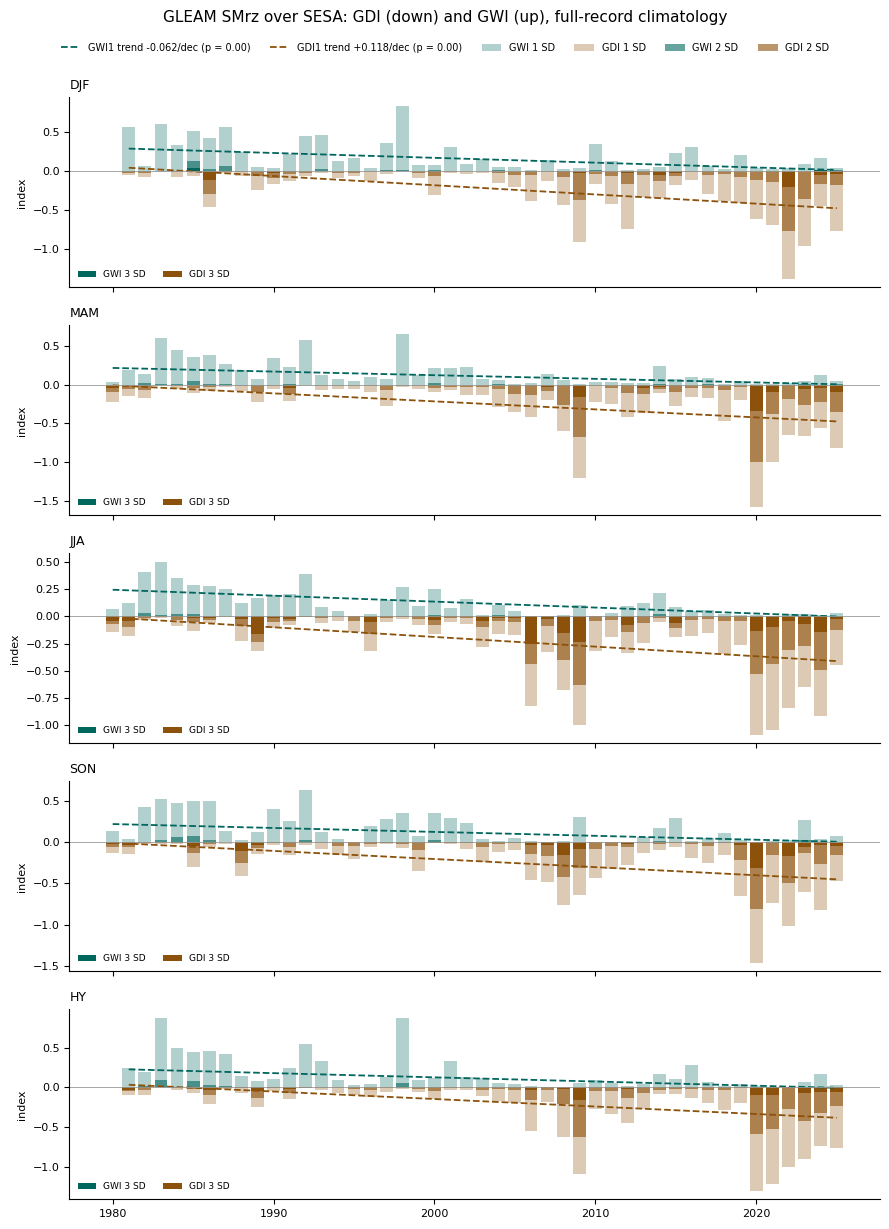

In [14]:
C_DRY, C_WET = "#8c510a", "#01665e"
LEVEL_ALPHA = {1: 0.30, 2: 0.60, 3: 1.0}

fig, axes = plt.subplots(len(GDI_PERIODS), 1, figsize=(9, 2.4 * len(GDI_PERIODS)), sharex=True)
for ax, p in zip(np.atleast_1d(axes), GDI_PERIODS):
    ds = gdgw[p]
    t = ds["year"].values
    for L in GDI_LEVELS:                      # level 1 >= level 2 >= level 3, so draw 1 first
        ax.bar(t, ds[f"GWI{L}"], color=C_WET, alpha=LEVEL_ALPHA[L], width=0.8, linewidth=0, label=f"GWI {L} SD")
        ax.bar(t, -ds[f"GDI{L}"], color=C_DRY, alpha=LEVEL_ALPHA[L], width=0.8, linewidth=0, label=f"GDI {L} SD")
    for name, sign, col in [("GWI1", 1, C_WET), ("GDI1", -1, C_DRY)]:
        v = ds[name].values
        s_, p_ = sen_mk(t, v)
        fit = np.median(v - s_[0] * t) + s_[0] * t
        ax.plot(t, sign * fit, color=col, lw=1.3, ls="--",
                label=f"{name} trend {s_[0] * 10:+.3f}/dec (p = {p_[0]:.2f})")
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_title(f"{p}", fontsize=9, loc="left")
    ax.set_ylabel("index", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes = np.atleast_1d(axes)
for ax in axes:                                   # trend lines: per panel
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[6:], l[6:], fontsize=6.5, frameon=False, loc="lower left", ncol=2)
handles, labels = axes[0].get_legend_handles_labels()   # bars: one shared legend
fig.legend(handles[:6], labels[:6], fontsize=7, frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.0))
fig.suptitle("GLEAM SMrz over SESA: GDI (down) and GWI (up), full-record climatology", fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_smrz_gdi_gwi.png"), dpi=200, bbox_inches="tight")
plt.show()

## Reversal test on the SESA box mean
Slopes are in standard deviations per decade. `p_break` < 0.05 means a two-segment trend fits significantly better than one straight line, even after allowing for the breakpoint search and year-to-year persistence.

In [10]:
results = {}
for s in SEASONS:
    y = box[s]
    results[s] = reversal_test(y["year"].values, y.values)

cols = ["reversal", "break_year", "break_ci", "pre_slope", "pre_ci", "post_slope", "post_ci",
        "p_break", "frac_boot_same_reversal", "sen_full", "p_full", "sen_pre", "p_pre", "sen_post", "p_post", "ar1"]
table = pd.DataFrame({s: {c: r[c] for c in cols} for s, r in results.items()}).T
table.to_csv(os.path.join(OUT_DIR, "sesa_gleam_smrz_reversal_box.csv"))
table

,reversal,break_year,break_ci,pre_slope,pre_ci,post_slope,post_ci,p_break,frac_boot_same_reversal,sen_full,p_full,sen_pre,p_pre,sen_post,p_post,ar1
ANN,wet→dry,1992,"[1989, 2016]",0.091687,"[-0.969, 1.517]",-0.876365,"[-2.067, -0.049]",0.454545,0.504,-0.695352,0.0,0.190321,0.94533,-0.876306,0.0,0.553582
DJF,no sign change,1993,"[1990, 2016]",-0.171333,"[-0.964, 0.964]",-0.840171,"[-1.873, 0.026]",0.48951,0.646,-0.70821,0.0,-0.029341,0.631222,-0.896423,0.00001,0.21352
MAM,wet→dry,1992,"[1989, 2016]",0.152626,"[-0.774, 1.357]",-0.796723,"[-1.781, -0.203]",0.23976,0.574,-0.62957,0.0,0.192852,0.94533,-0.780712,0.000002,0.272288
JJA,wet→dry,1991,"[1989, 2016]",0.019839,"[-1.079, 1.357]",-0.809568,"[-2.2, 0.429]",0.695305,0.425,-0.6429,0.0,-0.051962,0.640429,-0.819499,0.0,0.547755
SON,wet→dry,1992,"[1989, 2016]",0.007933,"[-1.069, 1.289]",-0.827291,"[-2.124, 0.118]",0.586414,0.445,-0.671296,0.0,0.19455,0.94533,-0.815839,0.0,0.554425


## Figure: box-mean series with single-line and hinge fits

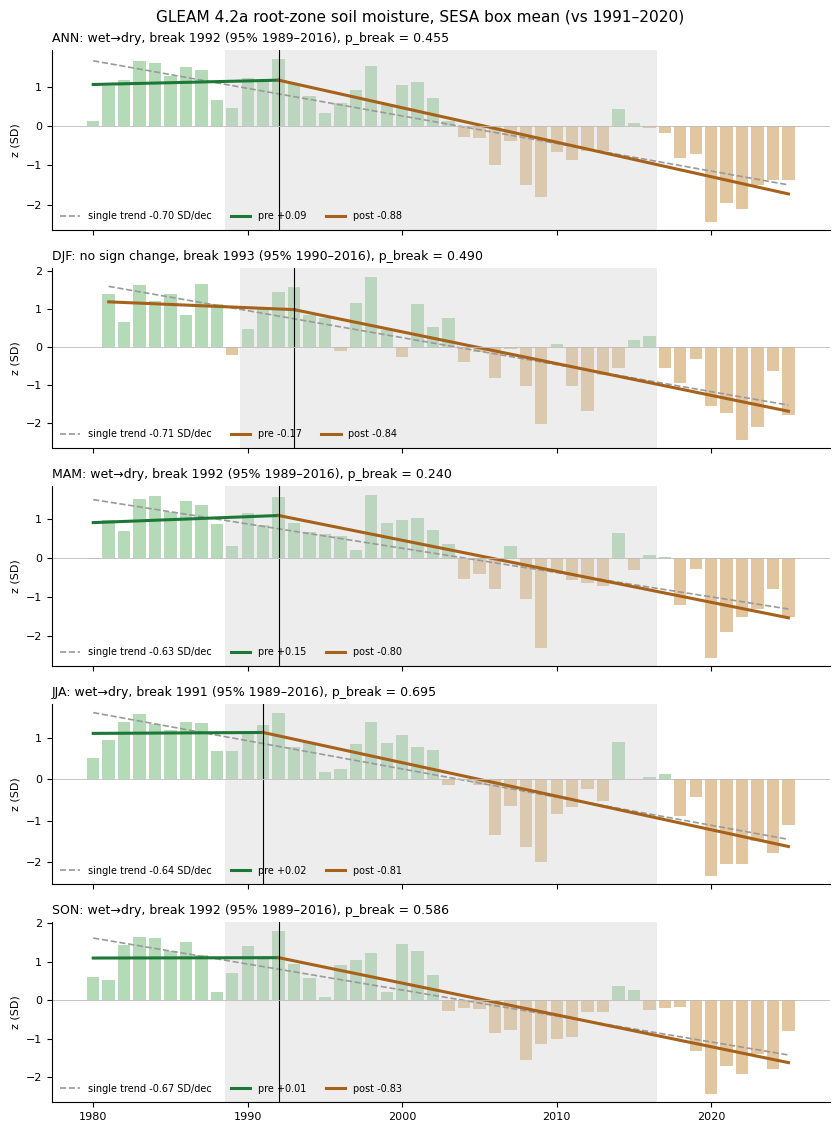

In [11]:
C_OBS, C_LIN, C_PRE, C_POST = "#333333", "#9a9a9a", "#1b7837", "#a6611a"   # green = wetting, brown = drying

fig, axes = plt.subplots(len(SEASONS), 1, figsize=(8.5, 2.3 * len(SEASONS)), sharex=True)
for ax, s in zip(np.atleast_1d(axes), SEASONS):
    y, r = box[s], results[s]
    t = y["year"].values.astype(float)
    f = r["_fit"]
    ax.bar(t, y.values, color=np.where(y.values >= 0, "#5aae61", "#bf812d"), width=0.8, alpha=0.45, linewidth=0)
    ax.plot(t, np.polyval(r["_lin"], t), color=C_LIN, lw=1.2, ls="--", label=f"single trend {r['sen_full']:+.2f} SD/dec")
    yh = f["pre"] * (t - t.mean()) + (f["post"] - f["pre"]) * np.maximum(t - f["tb"], 0)
    yh = yh + (y.values - yh).mean()
    pre, post = t <= f["tb"], t >= f["tb"]
    ax.plot(t[pre], yh[pre], color=C_PRE if f["pre"] > 0 else C_POST, lw=2.2, label=f"pre {r['pre_slope']:+.2f}")
    ax.plot(t[post], yh[post], color=C_POST if f["post"] < 0 else C_PRE, lw=2.2, label=f"post {r['post_slope']:+.2f}")
    lo, hi = r["break_ci"]
    ax.axvspan(lo - 0.5, hi + 0.5, color="#cccccc", alpha=0.35, linewidth=0)
    ax.axvline(f["tb"], color="k", lw=0.8)
    ax.axhline(0, color="#bbbbbb", lw=0.6)
    ax.set_title(f"{s}: {r['reversal']}, break {r['break_year']} (95% {lo}–{hi}), p_break = {r['p_break']:.3f}",
                 fontsize=9, loc="left")
    ax.set_ylabel("z (SD)", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=7, frameon=False, ncol=3, loc="lower left")
fig.suptitle("GLEAM 4.2a root-zone soil moisture, SESA box mean (vs 1991–2020)", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_smrz_hinge_fits.png"), dpi=200)
plt.show()

## Figure: trend triangle
Sen slope for every window of at least 10 years (x = start, y = end). A reversal shows up as wetting colours for early windows and drying colours for late ones; dots mark Mann-Kendall p < 0.05.

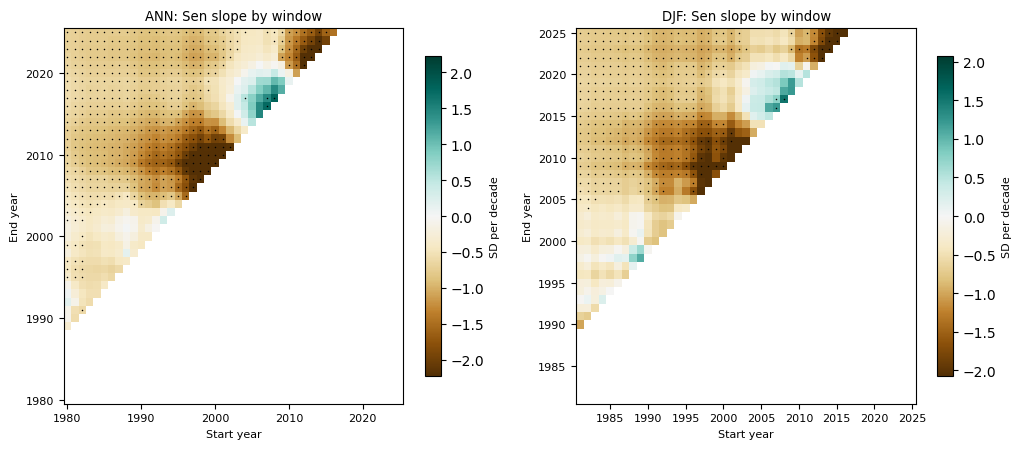

In [7]:
def trend_triangle(y, min_len=10):
    yrs = y["year"].values
    v = y.values
    n = len(yrs)
    S = np.full((n, n), np.nan)
    P = np.full((n, n), np.nan)
    for a in range(n):
        for b in range(a + min_len - 1, n):
            s_, p_ = sen_mk(yrs[a:b + 1], v[a:b + 1])
            S[b, a], P[b, a] = s_[0] * 10, p_[0]
    return yrs, S, P


tri_seasons = ["ANN", "DJF"]
fig, axes = plt.subplots(1, len(tri_seasons), figsize=(5.2 * len(tri_seasons), 4.6), squeeze=False)
for ax, s in zip(axes[0], tri_seasons):
    yrs, S, P = trend_triangle(box[s])
    vmax = np.nanpercentile(np.abs(S), 97)
    pc = ax.pcolormesh(yrs, yrs, S, cmap="BrBG", vmin=-vmax, vmax=vmax, shading="nearest")
    jj, ii = np.where(P < ALPHA)
    ax.scatter(yrs[ii], yrs[jj], s=1.2, c="k", linewidths=0)
    ax.set_xlabel("Start year", fontsize=8)
    ax.set_ylabel("End year", fontsize=8)
    ax.set_title(f"{s}: Sen slope by window", fontsize=9.5)
    ax.tick_params(labelsize=8)
    cb = fig.colorbar(pc, ax=ax, shrink=0.85)
    cb.set_label("SD per decade", fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "sesa_smrz_trend_triangle.png"), dpi=200)
plt.show()

## Gridded analysis
Each cell gets z-scores and the hinge fit. **Fixed break:** slopes before and after the box-mean breakpoint for `MAP_SEASON` (Sen + MK per segment). **Free break:** each cell's own best breakpoint year (no significance test per cell; the Monte Carlo is run only for the box mean).

In [8]:
g = standardise(seasonal(sm, MAP_SEASON))
g = g.where(g.notnull().sum("year") >= 0.8 * g.sizes["year"])          # mostly-complete land cells
yrs = g["year"].values.astype(float)
Y = g.transpose("year", "lat", "lon").values.reshape(len(yrs), -1)
valid = np.isfinite(Y).all(0)

tb_box = results[MAP_SEASON]["break_year"]
pre_m, post_m = yrs <= tb_box, yrs >= tb_box

shape = (g.sizes["lat"], g.sizes["lon"])
def empty():
    return np.full(Y.shape[1], np.nan)

s_pre, p_pre, s_post, p_post, tb_cell = empty(), empty(), empty(), empty(), empty()
a, b = sen_mk(yrs[pre_m], Y[pre_m][:, valid]);  s_pre[valid], p_pre[valid] = a * 10, b
a, b = sen_mk(yrs[post_m], Y[post_m][:, valid]); s_post[valid], p_post[valid] = a * 10, b
hf = hinge_fit(yrs, Y[:, valid])
tb_cell[valid] = np.where(np.sign(hf["pre"]) != np.sign(hf["post"]), hf["tb"], np.nan)  # only where the sign flips

# reversal class: 2 = wet→dry, -2 = dry→wet (both segments significant); ±1 = sign flip, not both significant; 0 = none
sig = (p_pre < ALPHA) & (p_post < ALPHA)
cls = np.where(valid, 0.0, np.nan)
cls[(s_pre > 0) & (s_post < 0)] = 1
cls[(s_pre < 0) & (s_post > 0)] = -1
cls[(s_pre > 0) & (s_post < 0) & sig] = 2
cls[(s_pre < 0) & (s_post > 0) & sig] = -2

coords = dict(lat=g["lat"], lon=g["lon"])
maps = xr.Dataset({k: (("lat", "lon"), v.reshape(shape)) for k, v in dict(
    slope_pre=s_pre, p_pre=p_pre, slope_post=s_post, p_post=p_post, reversal_class=cls, break_year_cell=tb_cell).items()},
    coords=coords)
maps.attrs.update(season=MAP_SEASON, break_year_box=tb_box, units_slope="SD per decade")
maps.to_netcdf(os.path.join(OUT_DIR, f"sesa_gleam_smrz_reversal_maps_{MAP_SEASON}.nc"))
print(f"break year (box, {MAP_SEASON}) = {tb_box}; cells: {int(valid.sum())}")

break year (box, ANN) = 1992; cells: 150084


## Figure: maps (Robinson)

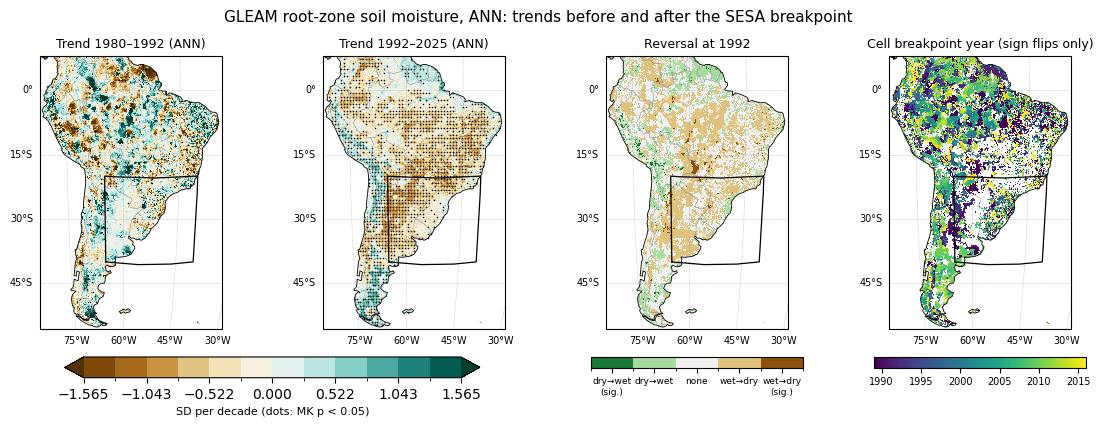

In [9]:
def map_ax(fig, pos):
    ax = fig.add_subplot(*pos, projection=ccrs.Robinson(central_longitude=-60))
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="#777777")
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.4, color="#999999", linestyle=":",
                      xlocs=range(-90, -20, 15), ylocs=range(-60, 20, 15))
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"size": 7}
    (la0, la1), (lo0, lo1) = REGION["lat"], REGION["lon"]
    ax.plot([lo0, lo1, lo1, lo0, lo0], [la0, la0, la1, la1, la0], color="k", lw=0.9, transform=ccrs.Geodetic())
    return ax


def stipple(ax, mask):
    yy, xx = np.meshgrid(maps["lat"].values, maps["lon"].values, indexing="ij")
    m = np.asarray(mask, bool)
    step = max(1, int(round(0.75 / float(np.abs(np.diff(maps["lat"].values)).mean()))))   # thin dots on fine grids
    thin = np.zeros_like(m)
    thin[::step, ::step] = True
    ax.scatter(xx[m & thin], yy[m & thin], s=1.2, c="k", linewidths=0, transform=ccrs.PlateCarree())


y0, y1 = int(yrs.min()), int(yrs.max())
fig = plt.figure(figsize=(14, 4.6))
vmax = float(np.nanpercentile(np.abs(np.r_[s_pre, s_post]), 97))
norm = mcolors.BoundaryNorm(np.linspace(-vmax, vmax, 13), 256, extend="both")

for k, (var, pv, title) in enumerate([("slope_pre", "p_pre", f"{y0}–{tb_box}"), ("slope_post", "p_post", f"{tb_box}–{y1}")]):
    ax = map_ax(fig, (1, 4, k + 1))
    pc = ax.pcolormesh(maps["lon"], maps["lat"], maps[var], cmap="BrBG", norm=norm, shading="nearest",
                       transform=ccrs.PlateCarree())
    stipple(ax, maps[pv] < ALPHA)
    ax.set_title(f"Trend {title} ({MAP_SEASON})", fontsize=9)
cb = fig.colorbar(pc, ax=fig.axes[:2], orientation="horizontal", shrink=0.8, pad=0.08)
cb.set_label("SD per decade (dots: MK p < 0.05)", fontsize=8)

ax = map_ax(fig, (1, 4, 3))
cmap = mcolors.ListedColormap(["#1b7837", "#a6dba0", "#f0f0f0", "#dfc27d", "#8c510a"])
pc3 = ax.pcolormesh(maps["lon"], maps["lat"], maps["reversal_class"], cmap=cmap,
                    norm=mcolors.BoundaryNorm([-2.5, -1.5, -0.5, 0.5, 1.5, 2.5], 5), shading="nearest",
                    transform=ccrs.PlateCarree())
ax.set_title(f"Reversal at {tb_box}", fontsize=9)
cb3 = fig.colorbar(pc3, ax=ax, orientation="horizontal", shrink=0.9, pad=0.08, ticks=[-2, -1, 0, 1, 2])
cb3.ax.set_xticklabels(["dry→wet\n(sig.)", "dry→wet", "none", "wet→dry", "wet→dry\n(sig.)"], fontsize=6.5)

ax = map_ax(fig, (1, 4, 4))
pc4 = ax.pcolormesh(maps["lon"], maps["lat"], maps["break_year_cell"], cmap="viridis", shading="nearest",
                    vmin=yrs[MIN_SEG - 1], vmax=yrs[-MIN_SEG], transform=ccrs.PlateCarree())
ax.set_title("Cell breakpoint year (sign flips only)", fontsize=9)
cb4 = fig.colorbar(pc4, ax=ax, orientation="horizontal", shrink=0.9, pad=0.08)
cb4.ax.tick_params(labelsize=7)

fig.suptitle(f"GLEAM root-zone soil moisture, {MAP_SEASON}: trends before and after the SESA breakpoint", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, f"sesa_smrz_reversal_maps_{MAP_SEASON}.png"), dpi=200, bbox_inches="tight")
plt.show()